# Problem

## Measured TCV plasma radiation tomography

We reconstruct all 190 author-distributed frames of discharge 85270, recorded during the 2025 TCV campaign. The unknown is an asymmetric poloidal emissivity field in W/m³. Five foil-bolometer cameras provide 120 channels; 113 are independently marked usable. We assume toroidal symmetry only.

**No physical ground truth is available.** The comparison image is an independently executed author offline MAP reconstruction. All images labeled fresh below are actively computed here. No cache-preview substitutes for reconstruction.

The selected published estimator is the offline LIUQE-informed MAP comparison. An independent derivative check identified a defect in the author's separate realtime reduced-vessel gradient; we retain that diagnostic below rather than describe the realtime method as validated.

In [1]:
import os,sys,time,json
from pathlib import Path
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[key]='1'
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
os.chdir(ROOT)
sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from src.preprocessing import load_data,prepare
from src.solvers import reconstruct,reconstruct_frame
from src.physics_model import gradient_matrix,integrate_power
from src import visualization as vis
data=load_data()
print('Full observation shape:',data['bolometer'].shape)
print('Time interval (s):',data['time'][[0,-1]])
print('Good channels:',len(data['good_channels']))

Full observation shape: (190, 120)
Time interval (s): [0.01001822 1.90001815]
Good channels: 113


# Data

The raw NPZ preserves native float64 bolometer readings, independently calculated geometric response, detector étendues, vessel support, and the native magnetic coordinate grids. Magnetic LIUQE measurements and FBT plans constrain smoothness orientation; neither is inferred from the hidden radiation image. No observation is resampled, thinned, or replaced by synthetic counts.

The response coverage plot shows why sparse projections cannot uniquely determine a2D image. The temporal channel image retains every native sample, including imperfect measurements.

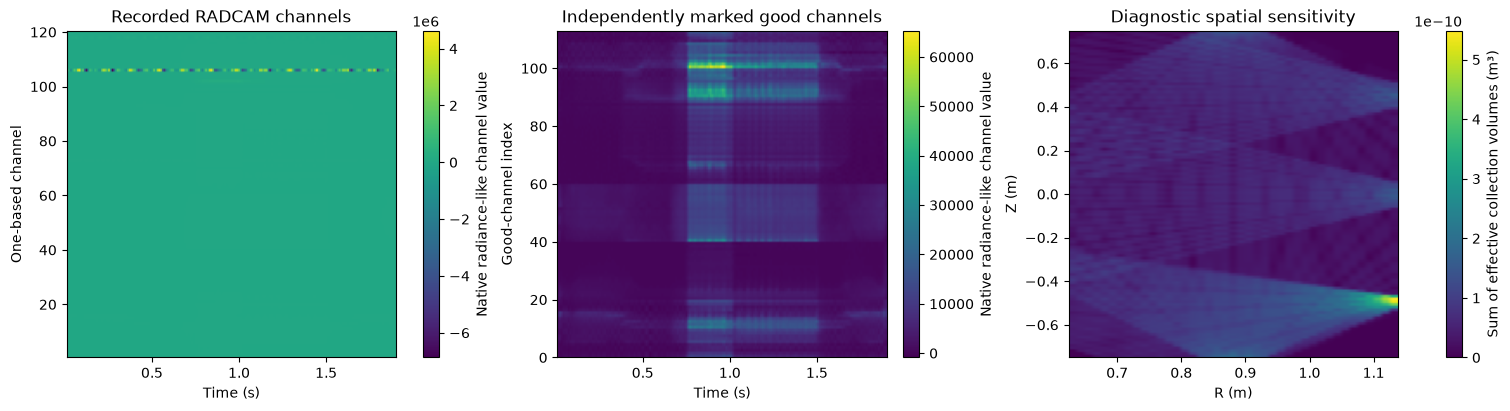

In [2]:
vis.observation_plot(data)
plt.show()

# Physics

Detector power is $P=4\pi E b$, where $b$ is the native radiance-normalized measurement and $E$ is independently supplied étendue. The linear acquisition is $P=Gx+\epsilon$, where $G$ is the volume-response matrix and $x$ is emissivity. Scaling both sides by $1/\max(G)$ gives $y=Ax+e$ without changing $x$.

Toroidal integration uses $P_{rad}=\sum_{i,j}2\pi R_j\Delta R\Delta Z\,x_{ij}$, giving watts. The sparse geometry cannot determine fine structure from measurements alone; a magnetic smoothness prior and known vessel support supply conditional information.

The diffusion gradient stacks vertical and horizontal forward differences with zero derivative at the rectangular exterior. Its constant-image derivative must vanish. Support projection imposes zero exterior emissivity, while retaining gradients across the vessel edge. This is not a no-flux boundary on the curved vessel.

Original separate realtime derivative max: 80.0
Fresh offline full-grid constant derivative max: 0.0


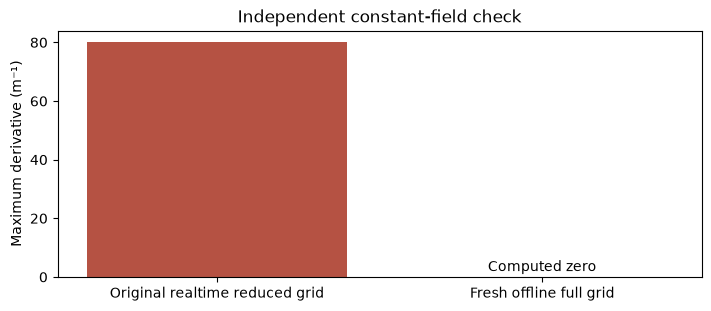

In [3]:
D=gradient_matrix((120,41))
fresh_constant_derivative=D@np.ones(120*41)
archived=np.load('test/fixtures/upstream_rt_gradient_diagnostic.npz',allow_pickle=False)['output_constant_derivative']
print('Original separate realtime derivative max:',np.max(abs(archived)))
print('Fresh offline full-grid constant derivative max:',np.max(abs(fresh_constant_derivative)))
fig,ax=plt.subplots(figsize=(7,3),layout='constrained')
ax.bar(['Original realtime reduced grid','Fresh offline full grid'],[np.max(abs(archived)),np.max(abs(fresh_constant_derivative))],color=['#b55243','#246782'])
ax.set(title='Independent constant-field check',ylabel='Maximum derivative (m⁻¹)')
ax.text(1,2,'Computed zero',ha='center')
plt.show()

# Method

Normalize each frame by its maximum good-channel value $q$, obtaining $z=y/q$. Minimize $J(u)=\|Au-z\|^2/(2\sigma^2)+\lambda u^T D^TWD u/2$ under the vessel support constraint; restore $x=qu$ afterward. Here $D$ is the image gradient, $W$ is a2-by2 diffusion tensor at every pixel, $\sigma=0.025$, and $\lambda=10$.

The central magnetic-flux gradient determines a normal and tangent direction. Tensor eigenvalues are0.01 normal to flux surfaces and1 along them. The original mean grid spacing convention is retained. Chambolle-Dossal projected acceleration uses momentum $k/(k+4)$ and a fixed conservative Lipschitz step. Initialization is the backprojection, and relative iterate change below$10^{-5}$ or10000 updates stops the frame.

We now execute the entire bound acquisition. The original run required103.48s in its isolated environment; the notebook timeout is1800s to allow complete reconstruction and fresh comparisons.

In [4]:
started=time.perf_counter()
fresh=reconstruct(data)
full_seconds=time.perf_counter()-started
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=fresh[None])
reference=np.load('evaluation/baseline_reference.npz',allow_pickle=False)['reconstruction'][0]
print('Fresh full reconstruction seconds:',full_seconds)
print('Fresh vs independently reproduced upstream:',vis.metrics(fresh,reference))
upstream_measurements=np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False)
print('Independently reproduced upstream maximum normalized residual:',upstream_measurements['normalized_residual'].max())
assert fresh.shape==(190,120,41)
import importlib.util
spec=importlib.util.spec_from_file_location('judge','evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate('output/reconstruction.npz')
Path('output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(report,indent=2))
assert report['passed']

Fresh full reconstruction seconds: 81.43508830002975
Fresh vs independently reproduced upstream: {'ncc': 1.0000000000000004, 'nrmse': 2.531985758753277e-16}
Independently reproduced upstream maximum normalized residual: 0.030576372875822475
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000004,
    "nrmse": 2.531985758753277e-16,
    "max_normalized_observation_rmse": 0.03057637287582246,
    "outside_vessel_max": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "max_normalized_observation_rmse": {
      "comparison": "<=",
      "boundary": 0.035
    },
    "outside_vessel_max": {
      "comparison": "<=",
      "boundary": 0.0
    }
  },
  "errors": []
}


# Results

The maps below compare independently reproduced upstream estimates with fresh local reconstructions. The first two rows share a physical color scale; the third shows their signed differences and has its own clearly labeled scale. Agreement validates extraction, not spatial accuracy. Negative Gaussian estimates and residual structures remain visible in the diagnostics.

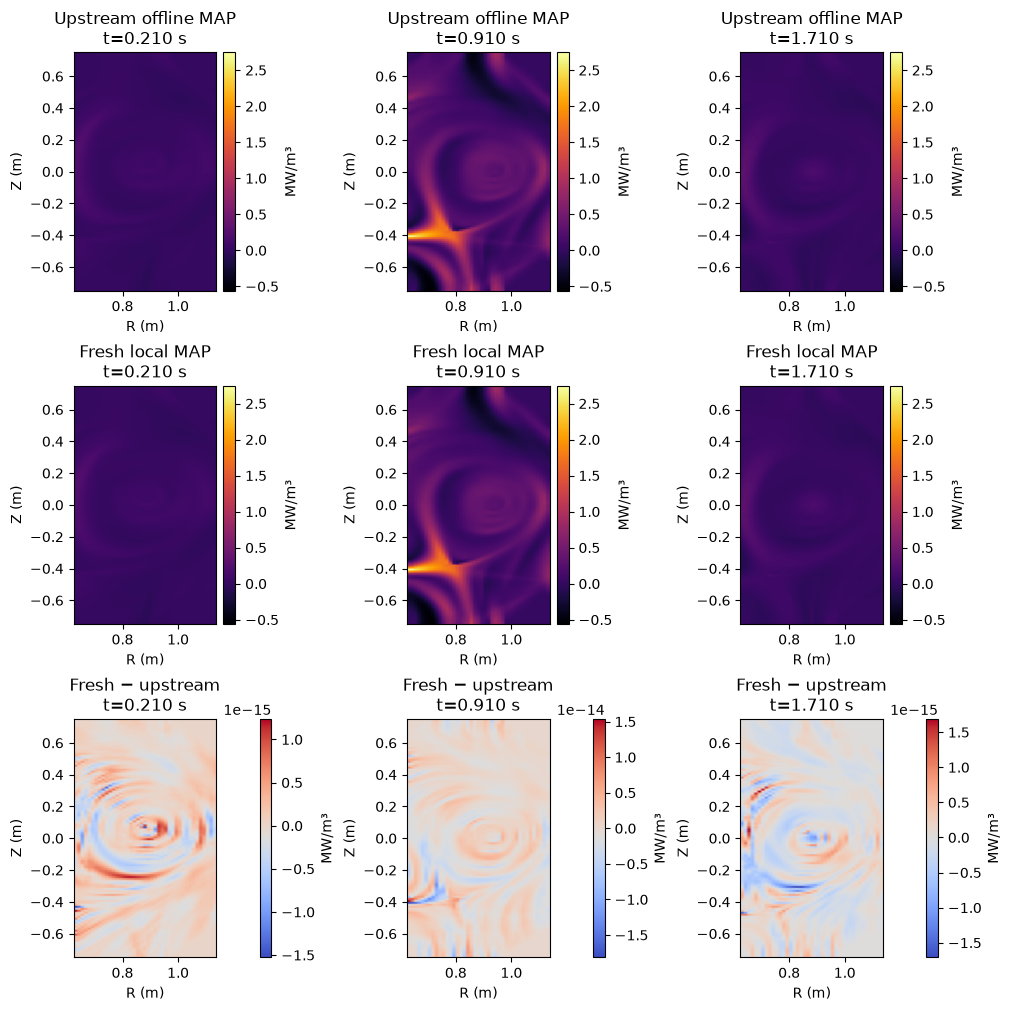

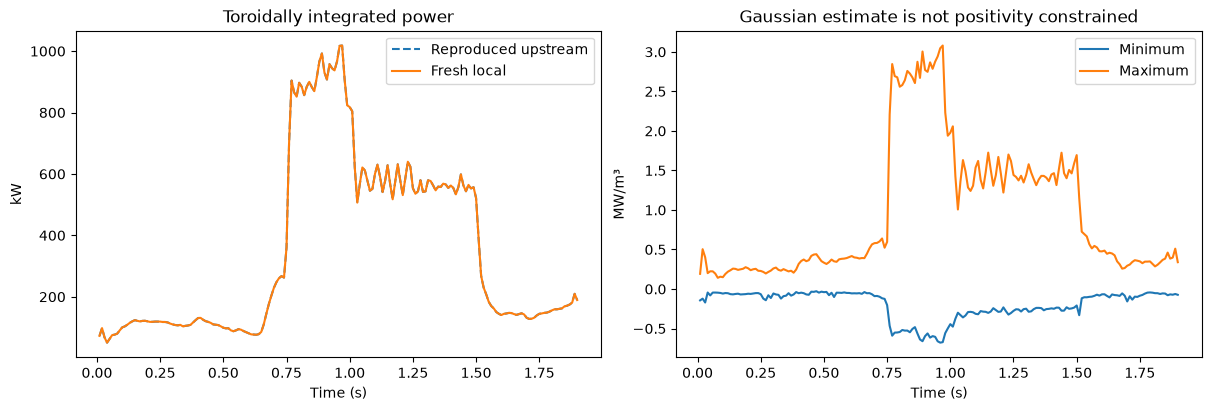

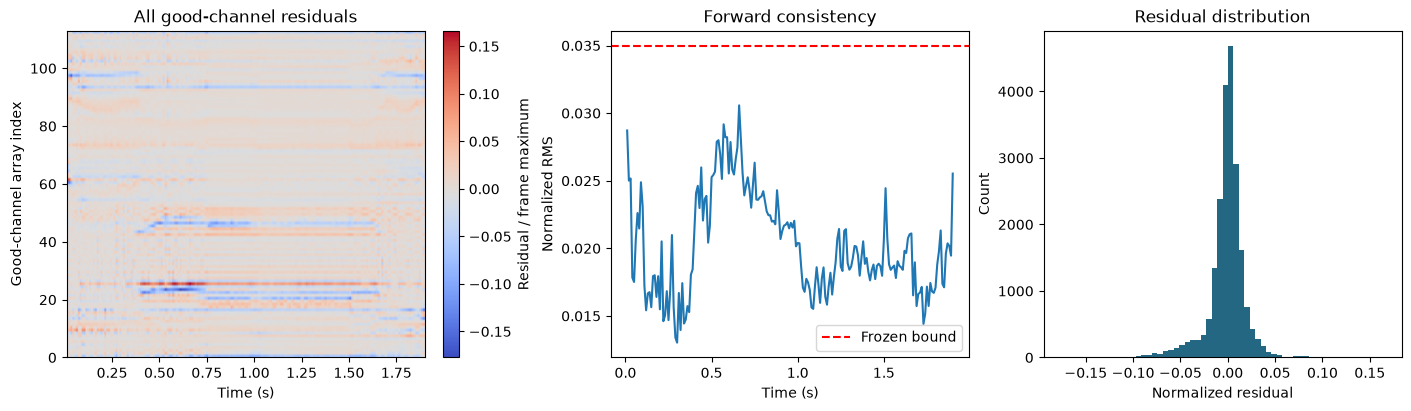

In [5]:
vis.reconstruction_plot(fresh,reference,data['time'])
plt.show()
vis.power_plot(data['time'],fresh,reference)
plt.show()
vis.residual_plot(data,fresh)
plt.show()

## Fresh scientific comparisons and convergence

At10 explicitly selected native frames spanning the discharge, we rerun three changes independently: isotropic diffusion, planned rather than measured magnetic equilibrium, and a positivity constraint. These are sensitivity experiments on the same measured data; they are not substitute benchmark observations or claimed ground truth. We retain the scientific question about planned versus measured equilibrium while documenting why the separate defective realtime-gradient implementation is excluded from validated reconstruction.

Forward residual alone does not rank spatial truth: stronger priors and positivity can alter radiation localization. The final convergence panel shows the actively computed objective and relative iterate change for a representative frame.

Measured anisotropic {'ncc': 0.9999999999999996, 'nrmse': 0.0} power range W 72619.34945457266 882928.345616003
Isotropic {'ncc': 0.8253840007809502, 'nrmse': 0.03261110560973566} power range W 69103.89570220993 854059.2981184332
Planned magnetic field {'ncc': 0.9910351423352032, 'nrmse': 0.007719473969288189} power range W 74823.58831500981 872912.2687080071
Positive estimate {'ncc': 0.9585428180755996, 'nrmse': 0.016476381748865523} power range W 67802.2773700694 825249.8391702252
Fresh comparison runtimes (s): {'Isotropic': 2.372313700034283, 'Planned magnetic field': 4.310073200031184, 'Positive estimate': 4.201382600003853}


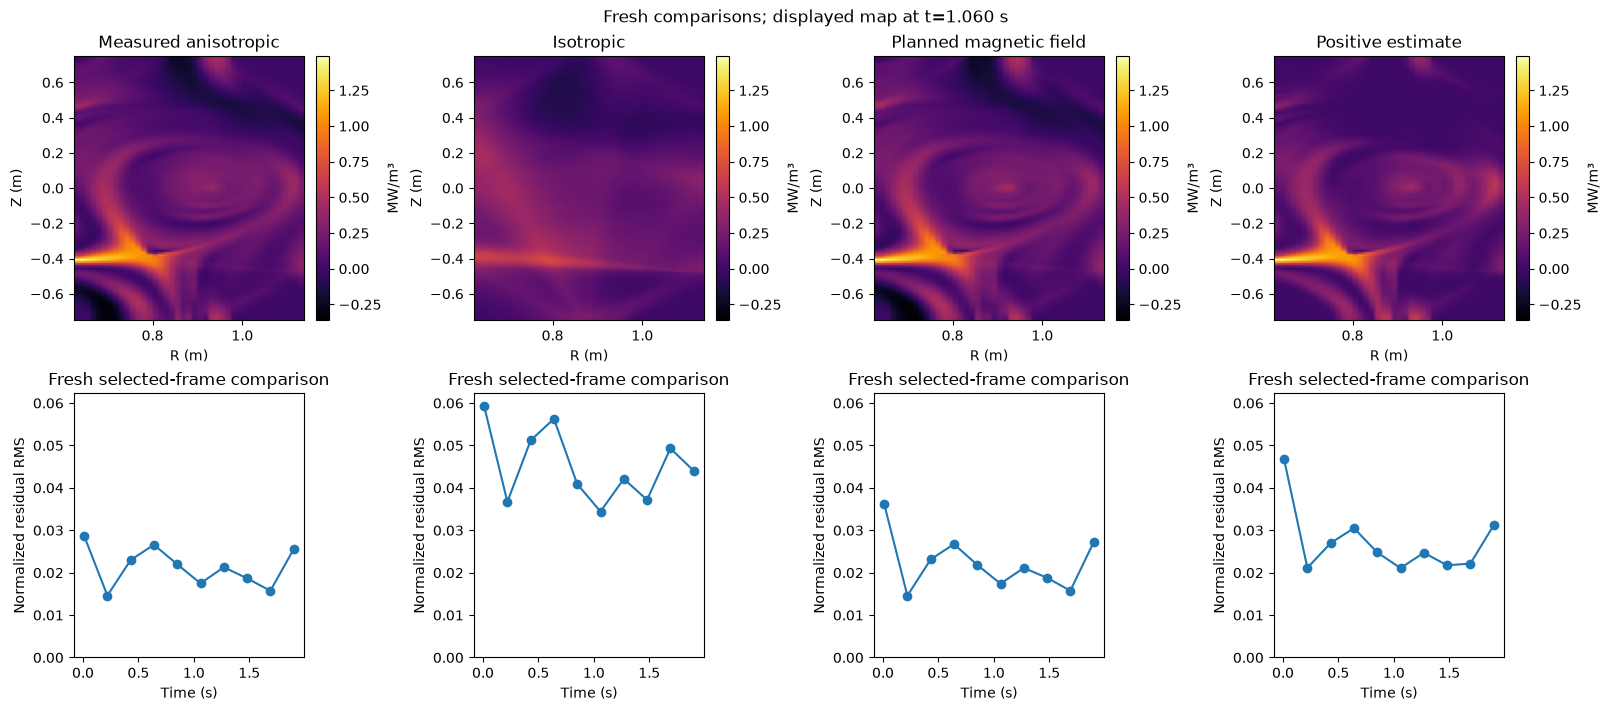

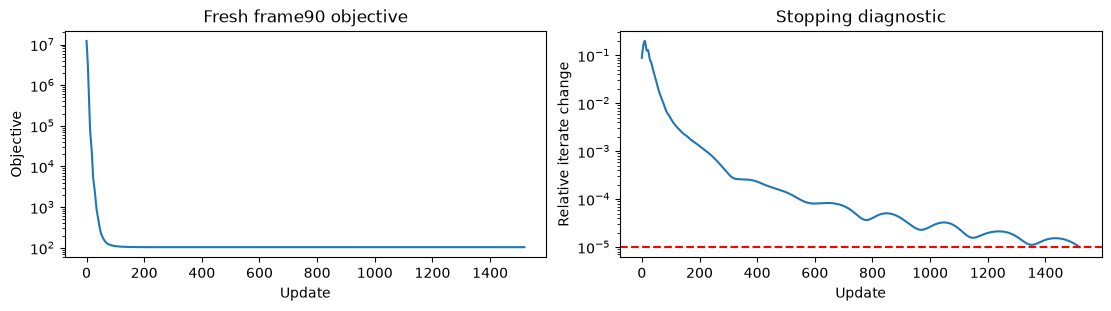

All190 default frames and all comparison images were actively computed.


In [6]:
indices=np.linspace(0,len(fresh)-1,10,dtype=int)
methods={'Measured anisotropic':fresh[indices]}
runtimes={}
for label,kwargs in [('Isotropic',{'alpha':1.}),('Planned magnetic field',{'equilibrium':'planned'}),('Positive estimate',{'positive':True})]:
    st=time.perf_counter();methods[label]=reconstruct(data,indices=indices,**kwargs);runtimes[label]=time.perf_counter()-st
for label,x in methods.items():
    print(label,vis.metrics(x,fresh[indices]),'power range W',integrate_power(x).min(),integrate_power(x).max())
print('Fresh comparison runtimes (s):',runtimes)
vis.ablation_plot(data,indices,methods)
plt.show()
a,y,flux,mask=prepare(data)
trace_image,trace=reconstruct_frame(a,y[90],flux[90],mask,return_history=True)
fig,axs=plt.subplots(1,2,figsize=(11,3),layout='constrained')
axs[0].semilogy(trace[:,0]);axs[0].set(title='Fresh frame90 objective',xlabel='Update',ylabel='Objective')
axs[1].semilogy(trace[:,1]);axs[1].axhline(1e-5,color='r',ls='--');axs[1].set(title='Stopping diagnostic',xlabel='Update',ylabel='Relative iterate change')
plt.show()
np.savez_compressed('notebooks/reference_outputs/fresh_measurements.npz',full_runtime_seconds=np.array(full_seconds),ncc=np.array(vis.metrics(fresh,reference)['ncc']),nrmse=np.array(vis.metrics(fresh,reference)['nrmse']),comparison_indices=indices,comparison_power=np.array([integrate_power(x) for x in methods.values()]),objective_trace=trace)
print('All190 default frames and all comparison images were actively computed.')

# Conclusion

The fresh local implementation reconstructs the complete measured discharge and is checked against an independently executed offline standard estimator, stage fixtures, analytic gradient/adjoint tests, and all-channel forward residuals. Planned-field, isotropic and positivity comparisons expose sensitivity to assumptions without inventing physical truth.

The separate realtime source routine fails a constant-field derivative check and is not called a validated method. Gaussian negative emissivity, sparse angular coverage, approximate noise scaling, mean-spacing derivatives and independent magnetic-equilibrium uncertainty limit physical interpretation. Standard-method agreement is reproducibility evidence, not a measurement of true local emissivity.